# Systematic Strategies: CTA, Risk Parity & Vol Targeting

Rules-based funds trade **mechanically**: they buy what trends, cut what gets volatile, and rebalance to fixed risk
budgets. Because their rules are knowable, their positioning, and the flows they will need, can be modelled. The
`global_systematic_flows` dataset does that across ~100 liquid futures:

| Strategy | Series | What drives it |
|---|---|---|
| **CTA / trend followers** | 108 | Price momentum over multiple lookbacks, scaled by volatility |
| **Risk parity** | 82 | Equal risk contribution across asset classes, levered to a volatility target |
| **Vol targeting** | 1 (S&P 500) | Equity exposure scaled inversely to realised volatility |

This notebook covers:

1. The universe and the modelled strategy AUM
2. CTA positioning today, and how stretched it is versus history
3. **Projected flows**: what the models expect these funds to trade over the next 1–10 days
4. Do the projections work? A check against what actually happened
5. CTA vs risk parity vs vol targeting in US equities
6. The cross-asset CTA book through time
7. Scenario projections from the API forecast cube

In [1]:
import sys
from pathlib import Path

from dotenv import load_dotenv

sys.path.insert(0, str(Path.cwd().parent))
load_dotenv(Path.cwd().parent / ".env")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import quantkit as qk

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
qk.set_style()

ASSET_COLORS = {"EQ": qk.VANDA["purple"], "FI": "#3b82f6", "FX": "#10b981", "COM": "#f59e0b"}
METRICS = ["exposure", "exposure_as_perc_aum", "net", "cum_net_1d", "cum_net_5d", "cum_net_10d", "exposure_5d"]

## 1. Universe

The dataset is large (~19M rows) because it carries many metrics per series. Load only what you need, and let
`qk.load` push the metric filter into the parquet scan.

In [2]:
raw = qk.load("flow", "global_systematic_flows", metrics=METRICS).dropna(subset=["value"])
ref = qk.series_reference().set_index("series_label")

wide = {m: qk.pivot(raw[raw.metric == m]) for m in METRICS}
universe = ref.loc[wide["exposure"].columns, ["name", "asset_type", "country", "investor_subtype", "entity", "benchmark"]].copy()
universe["level"] = np.where(universe.entity.str.contains("_") | universe.entity.str.isupper(), "bucket", "instrument")
universe["short_name"] = universe.name.str.replace(r"^(CTA|Risk Parity Funds|Risk Parity|Systematic)\s+", "", regex=True)

print(f"{len(universe)} series · {raw.ts.min():%Y-%m-%d} → {raw.ts.max():%Y-%m-%d}")
universe.groupby(["investor_subtype", "level"]).size().unstack(fill_value=0)

192 series · 2010-01-01 → 2026-04-10


level,bucket,instrument
investor_subtype,,
CTA,13,95
Mixed,1,0
Risk Parity,11,71
Vol targeting,0,1


**Bucket** series aggregate instruments into risk groups (`US_Equity`, `US_BE` = UST back end, `Energy_com`, ...).
**Instrument** series are single futures (`es1 index`, `ty1 comdty`, ...).

### Modelled AUM

`exposure` is in USD mn and `exposure_as_perc_aum` is a fraction of strategy AUM, so their ratio recovers the AUM each
model assumes. This is a useful sanity check, and the denominator you need to compare strategies:

In [3]:
latest = {m: w.ffill().iloc[-1] for m, w in wide.items()}
implied_aum = (latest["exposure"] / latest["exposure_as_perc_aum"]).replace([np.inf, -np.inf], np.nan) / 1_000
implied_aum.groupby(universe.investor_subtype).median().round(0).rename("median implied AUM (USD bn)").to_frame()

,median implied AUM (USD bn)
investor_subtype,
CTA,320.0
Mixed,552.0
Risk Parity,177.0
Vol targeting,141.0


## 2. CTA positioning today

Exposure as a share of AUM makes markets comparable. Next to today's level we show its **percentile in the series'
own history**: a CTA at 90% of its historical range is close to maximum long, and has more room to sell than to buy.

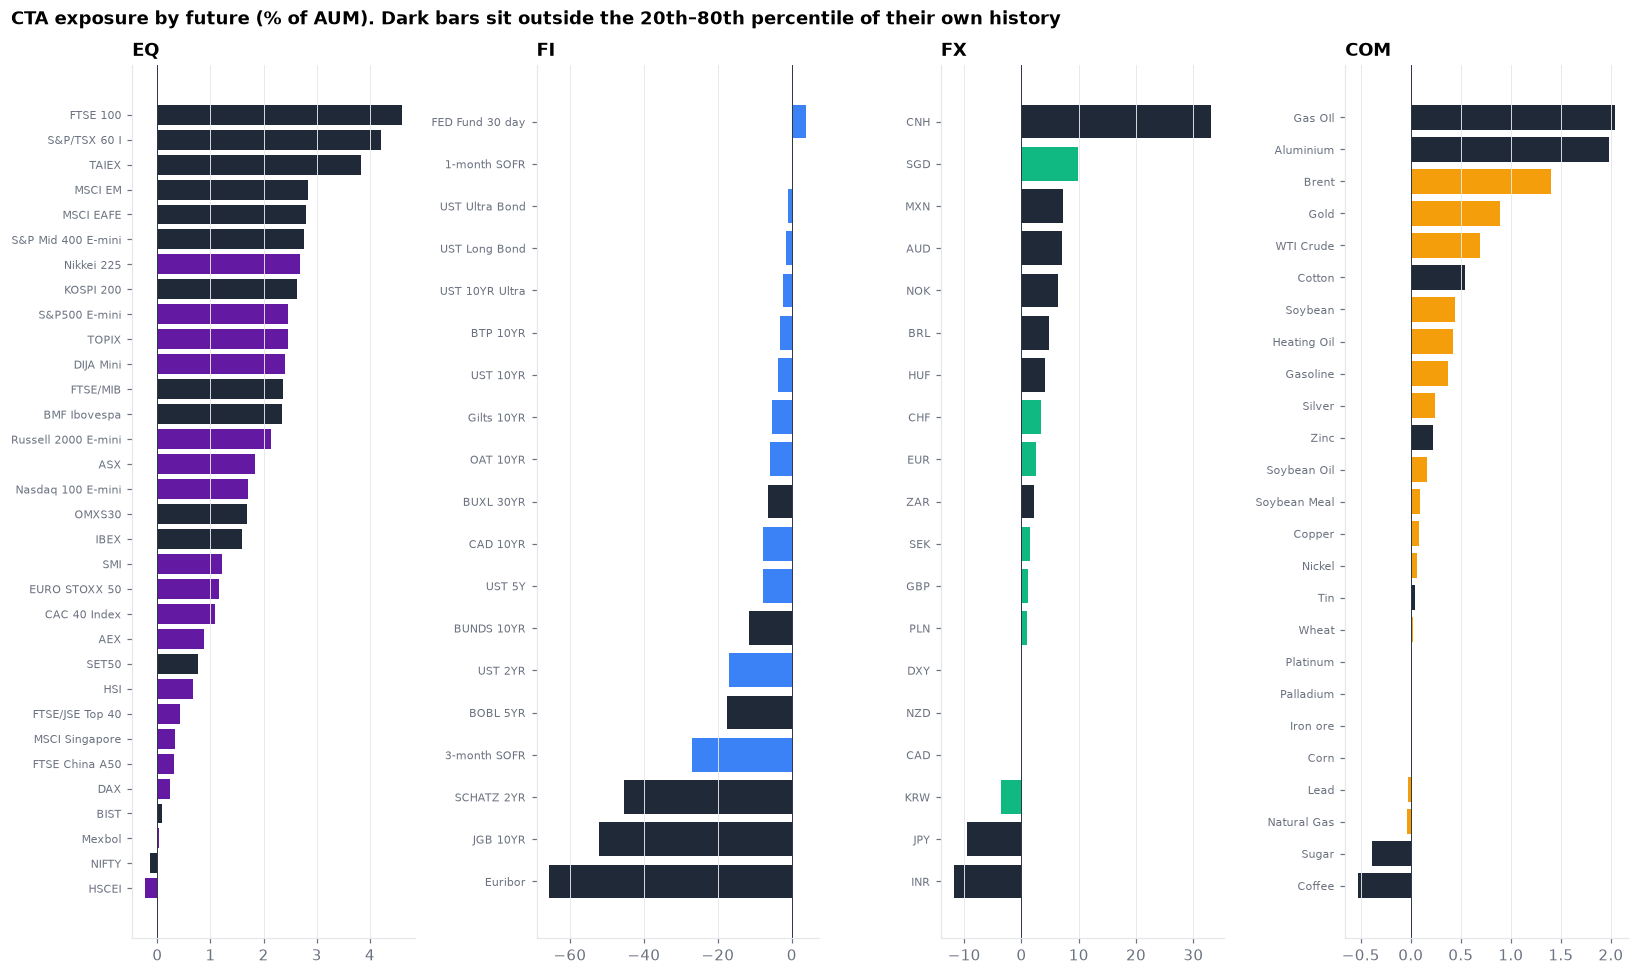

In [4]:
cta = universe[(universe.investor_subtype == "CTA") & (universe.level == "instrument")].index
pct_aum = wide["exposure_as_perc_aum"][cta]

today = pd.DataFrame({
    "name": universe.loc[cta, "short_name"],
    "asset": universe.loc[cta, "asset_type"],
    "pct_aum": pct_aum.ffill().iloc[-1] * 100,
    "hist_pct": pct_aum.apply(qk.percentile_of_last),
}).dropna()

fig, axes = plt.subplots(1, 4, figsize=(15, 9), sharex=False)
for ax, (asset, color) in zip(axes, ASSET_COLORS.items()):
    g = today[today.asset == asset].sort_values("pct_aum")
    ax.barh(g.name, g.pct_aum, color=[color if p >= 20 and p <= 80 else qk.VANDA["ink"] for p in g.hist_pct])
    ax.axvline(0, color=qk.VANDA["ink"], lw=0.6)
    ax.set_title(asset)
    ax.tick_params(axis="y", labelsize=7.5)
    ax.grid(axis="y", visible=False)
fig.suptitle("CTA exposure by future (% of AUM). Dark bars sit outside the 20th–80th percentile of their own history",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

In [5]:
print("Most stretched CTA positions versus their own history")
today.assign(extreme=(today.hist_pct - 50).abs()).nlargest(12, "extreme")[["name", "asset", "pct_aum", "hist_pct"]].round(1)

Most stretched CTA positions versus their own history


,name,asset,pct_aum,hist_pct
THEQFUTUBC1MIXINSSPECTA,SET50,EQ,0.8,99.5
BRFXFUTUBRLMIXINSSPECTA,BRL,FX,4.8,98.6
GLCOMFUTUCT1MIXINSSPECTA,Cotton,COM,0.5,97.4
EUFIFUTUER3MIXINSSPECTA,Euribor,FI,-65.5,3.4
AUFXFUTUAUDMIXINSSPECTA,AUD,FX,7.1,96.1
DEFIFUTUDU1MIXINSSPECTA,SCHATZ 2YR,FI,-45.4,4.0
BREQFUTUBZ1MIXINSSPECTA,BMF Ibovespa,EQ,2.4,96.0
GLCOMFUTUKC1MIXINSSPECTA,Coffee,COM,-0.5,4.1
NOFXFUTUNOKMIXINSSPECTA,NOK,FX,6.3,95.7
JPFIFUTUJB1MIXINSSPECTA,JGB 10YR,FI,-52.2,4.5


## 3. Projected flows: who has to trade next?

For each series the model projects exposure 1, 5 and 10 market days ahead in its **base case** (prices unchanged), and
the flow that implies: `cum_net_Nd = exposure_Nd − exposure`. This is the mechanical flow systematic funds would need to
execute just to stay on-model.

Large projected selling into a weak market is how CTA unwinds become self-reinforcing.

In [6]:
projected = pd.DataFrame({
    "strategy": universe.investor_subtype,
    "name": universe.short_name,
    "asset": universe.asset_type,
    "exposure $bn": latest["exposure"] / 1_000,
    "next 1d $bn": latest["cum_net_1d"] / 1_000,
    "next 5d $bn": latest["cum_net_5d"] / 1_000,
    "next 10d $bn": latest["cum_net_10d"] / 1_000,
})[universe.level == "instrument"]

print(f"Projected systematic flows as of {wide['exposure'].index.max():%d %b %Y}: largest 10-day buyers and sellers")
pd.concat([projected.nsmallest(8, "next 10d $bn"), projected.nlargest(8, "next 10d $bn")]).round(2)

Projected systematic flows as of 10 Apr 2026: largest 10-day buyers and sellers


,strategy,name,asset,exposure $bn,next 1d $bn,next 5d $bn,next 10d $bn
SGFXFUTUSGDMIXINSSPECTA,CTA,SGD,FX,31.75,2.43,1.66,-11.29
KRFXFUTUKRWMIXINSSPECTA,CTA,KRW,FX,-11.46,1.39,3.63,-7.13
JPFXFUTUJPYMIXINSSPECTA,CTA,JPY,FX,-30.55,3.95,3.25,-5.32
DEFIFUTUDU1MIXINSSPERP,Risk Parity,SCHATZ 2YR,FI,46.61,-0.86,-3.24,-5.05
NZFXFUTUNZDMIXINSSPECTA,CTA,NZD,FX,0.00,1.65,1.38,-3.84
GBFIFUTUG1MIXINSSPECTA,CTA,Gilts 10YR,FI,-16.73,1.06,-1.85,-3.28
USFIFUTUUS1MIXINSSPECTA,CTA,UST Long Bond,FI,-4.78,-2.08,-5.05,-3.02
CAFXFUTUCADMIXINSSPECTA,CTA,CAD,FX,0.00,3.37,1.61,-2.95
USFIFUTUSFRMIXINSSPECTA,CTA,3-month SOFR,FI,-86.38,5.83,-4.82,32.22
DEFIFUTUDU1MIXINSSPECTA,CTA,SCHATZ 2YR,FI,-145.26,11.67,15.62,16.46


In [7]:
by_asset = projected.groupby(["asset", "strategy"])[["next 5d $bn", "next 10d $bn"]].sum().unstack("strategy").round(1)
by_asset

next 5d $bn                           next 10d $bn                          
strategy         CTA Risk Parity Vol targeting          CTA Risk Parity Vol targeting
asset                                                                                
COM             -1.8        -0.1           NaN         -0.6        -0.1           NaN
EQ             -14.6        -0.7          -0.8         -4.2        -0.9          -1.4
FI              28.1        -3.7           NaN         89.2        -5.0           NaN
FX              15.0         NaN           NaN        -28.6         NaN           NaN

## 4. Do the projections work?

A projection is only useful if it anticipates what the funds then do. We compare each day's projected 5-day flow
(`cum_net_5d`) with the **realised** change in modelled exposure over the following five days, for every series.

In [8]:
exposure = wide["exposure"]
realised_5d = exposure.shift(-5) - exposure
check = []
for label in wide["cum_net_5d"].columns.intersection(exposure.columns):
    both = pd.concat({"projected": wide["cum_net_5d"][label], "realised": realised_5d[label]}, axis=1, sort=True).dropna()
    if len(both) > 500:
        check.append({"label": label, "asset": universe.at[label, "asset_type"], "strategy": universe.at[label, "investor_subtype"],
                      "corr": both.projected.corr(both.realised),
                      "direction right": (np.sign(both.projected) == np.sign(both.realised)).mean()})
check = pd.DataFrame(check)
check.groupby(["strategy", "asset"])[["corr", "direction right"]].median().round(2)

corr  direction right
strategy      asset                       
CTA           COM    0.48             0.64
              EQ     0.45             0.64
              FI     0.48             0.64
              FX     0.48             0.64
Risk Parity   COM    0.16             0.48
              EQ     0.18             0.51
              FI     0.14             0.49
Vol targeting EQ     0.25             0.55

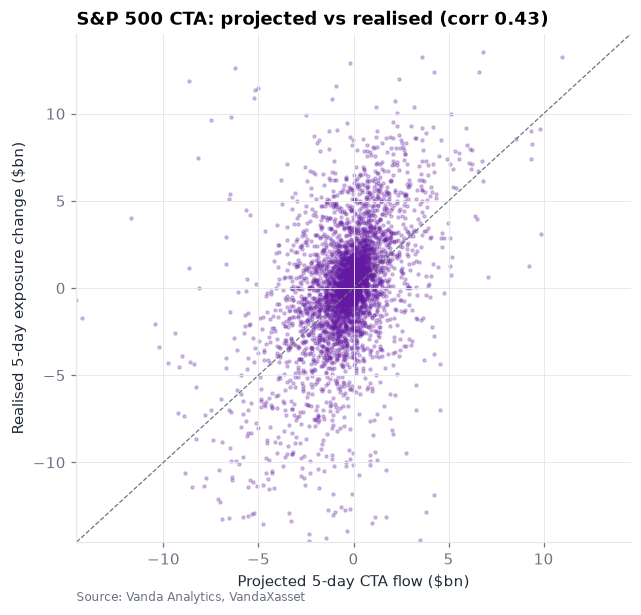

In [9]:
es = "USEQFUTUES1MIXINSSPECTA"
both = pd.concat({"projected": wide["cum_net_5d"][es], "realised": realised_5d[es]}, axis=1, sort=True).dropna() / 1_000
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(both.projected, both.realised, s=4, alpha=0.25, color=qk.VANDA["purple"])
lim = np.nanpercentile(both.abs().values, 99.5)
ax.plot([-lim, lim], [-lim, lim], color=qk.VANDA["sub"], lw=0.8, ls="--")
ax.set_xlim(-lim, lim)
ax.set_ylim(-lim, lim)
ax.set_xlabel("Projected 5-day CTA flow ($bn)")
ax.set_ylabel("Realised 5-day exposure change ($bn)")
ax.set_title(f"S&P 500 CTA: projected vs realised (corr {both.corr().iloc[0, 1]:.2f})")
qk.source_note(ax)
plt.show()

The answer depends on the strategy:

* **CTA projections are informative.** They are clearly positively correlated with what followed and get the direction
  right roughly two times in three, in every asset class.
* **Risk-parity and vol-targeting projections are much weaker.** These funds rebalance on volatility and on
  cross-asset risk budgets, which a flat-price base case cannot anticipate.

Even for CTAs the fit is imperfect, because the base case assumes **flat prices** and prices move. The forecast cube in
section 7 handles that by projecting under a grid of price scenarios.

## 5. Three kinds of systematic money in US equities

CTAs, risk-parity funds and vol-targeting funds all hold S&P 500 futures, for different reasons. They often de-risk at
the same time, in volatility spikes, which is what makes those episodes violent.

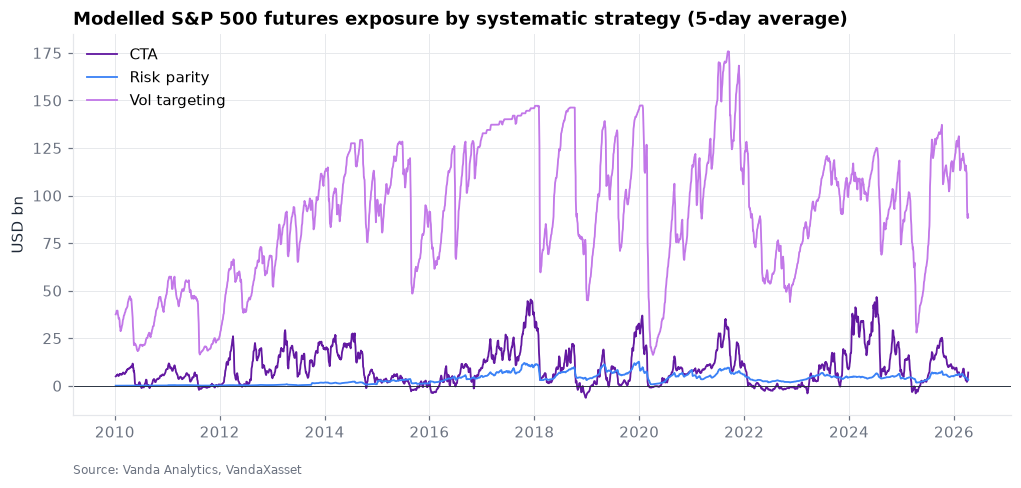

In [10]:
us_labels = {
    "CTA": "USEQFUTUES1MIXINSSPECTA",
    "Risk parity": "USEQFUTUES1MIXINSSPERP",
    "Vol targeting": "USEQFUTUES1MIXINSREAVT",
}
us = pd.DataFrame({k: exposure[v] for k, v in us_labels.items() if v in exposure}) / 1_000

fig, ax = plt.subplots()
for (label, s), color in zip(us.items(), [qk.VANDA["purple"], "#3b82f6", qk.VANDA["lilac"]]):
    ax.plot(s.index, s.rolling(5).mean(), label=label, color=color, lw=1.2)
ax.axhline(0, color=qk.VANDA["ink"], lw=0.6)
ax.set_ylabel("USD bn")
ax.set_title("Modelled S&P 500 futures exposure by systematic strategy (5-day average)")
ax.legend(loc="upper left")
qk.source_note(ax)
plt.show()

Selling pressure is highest when all three cut together. Count the days when every strategy's 5-day exposure change
was in the bottom decile of its own history:

In [11]:
change_5d = us.diff(5)
weak = change_5d.apply(lambda s: s <= s.quantile(0.10))
joint = weak.all(axis=1)
episodes = joint[joint & ~joint.shift(1, fill_value=False)].index
print(f"{joint.sum()} days of joint systematic de-risking, in {len(episodes)} episodes. Most recent starts:")
print(", ".join(d.strftime("%Y-%m-%d") for d in episodes[-10:]))

84 days of joint systematic de-risking, in 31 episodes. Most recent starts:
2024-08-05, 2024-08-08, 2024-11-06, 2024-12-18, 2025-04-07, 2025-08-06, 2025-10-13, 2026-02-09, 2026-03-12, 2026-03-18


## 6. The cross-asset CTA book through time

Bucket series summarise CTA exposure by risk group. Rates buckets carry far larger notional exposure than equities or
commodities, so a raw % AUM heatmap shows only rates. Colouring each bucket by the **percentile of its own history**
puts them on one scale. The deep short in front-end rates through the 2022 hiking cycle stands out, as do the swings
in FX and equity trend positioning since.

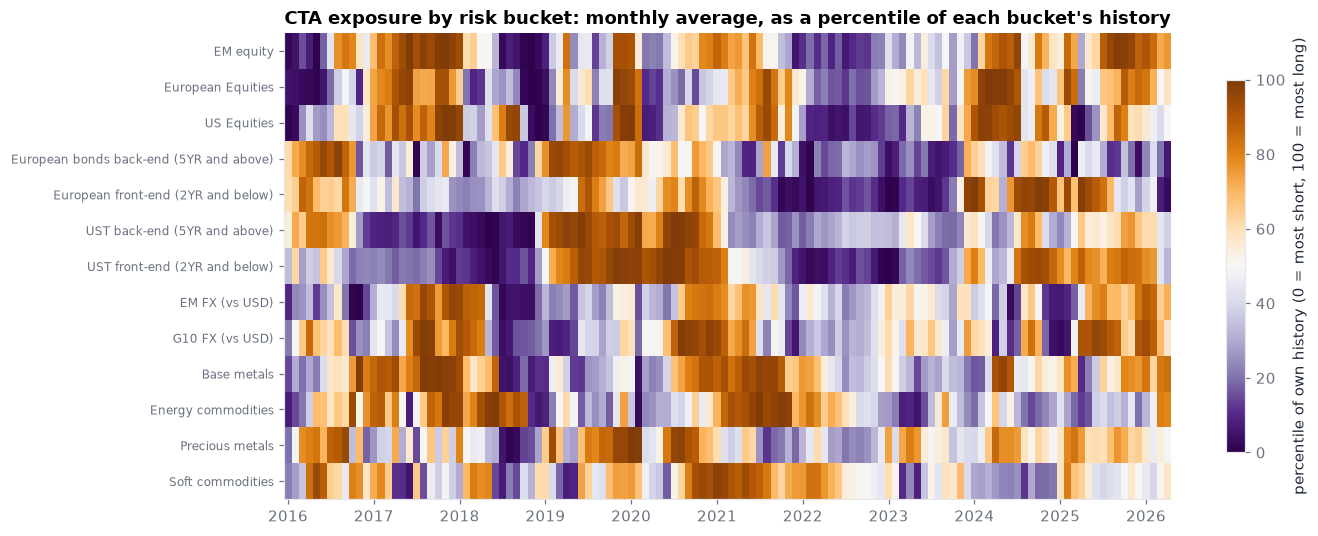

In [12]:
order = {"EQ": 0, "FI": 1, "FX": 2, "COM": 3}
buckets = (
    universe[(universe.investor_subtype == "CTA") & (universe.level == "bucket")]
    .assign(rank=lambda d: d.asset_type.map(order))
    .sort_values(["rank", "short_name"])
    .index
)
monthly = wide["exposure_as_perc_aum"][buckets].resample("ME").mean()
monthly.columns = universe.loc[buckets, "short_name"]
monthly = (monthly.rank(pct=True) * 100).loc["2016":]

fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(monthly.T.values, aspect="auto", cmap="PuOr_r", vmin=0, vmax=100)
ax.set_yticks(range(monthly.shape[1]), monthly.columns, fontsize=8)
years = [i for i, d in enumerate(monthly.index) if d.month == 1]
ax.set_xticks(years, [monthly.index[i].year for i in years])
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="percentile of own history (0 = most short, 100 = most long)")
ax.set_title("CTA exposure by risk bucket: monthly average, as a percentile of each bucket's history")
plt.show()

## 7. Scenario projections: the forecast cube (API)

The base-case projection assumes flat prices. The API also publishes a **forecast cube**: exposure projected for each
horizon (0–15 days) under a grid of price moves expressed as z-scores. It answers questions like *"how much would CTAs
sell if S&P falls 2σ over the next week?"*. The cube is API-only; notebook 01 §7 walks through it. A compact version:

In [13]:
if qk.has_api_credentials():
    client = qk.api_client()
    cube = client.flow.get_forecast(series_ids=us_labels["CTA"], components="cta", metrics="exposure_as_perc_aum",
                                    scenarios=["-2.0", "-1.0", "0.0", "1.0", "2.0"], horizons=[1, 5, 10, 15])
    grid = pd.DataFrame([{"scenario": g["scenario"], "horizon": g["horizon"], "% AUM": g["metrics"]["exposure_as_perc_aum"]["value"] * 100}
                         for g in cube["data"]]).pivot(index="scenario", columns="horizon", values="% AUM")
    grid = grid.loc[sorted(grid.index, key=float)]
    print(f"CTA S&P 500 exposure (% AUM) by price scenario and horizon, run {cube['run_date'][:10]}")
    display(grid.round(2))
else:
    print("Set VANDA_SDK_KEY in .env to pull the scenario cube from the API (see notebook 01, section 7).")

CTA S&P 500 exposure (% AUM) by price scenario and horizon, run 2026-10-09


horizon,1,5,10,15
scenario,,,,
-2.0,2.28,1.37,1.23,0.00
-1.0,2.76,2.17,2.15,1.10
0.0,3.18,2.96,3.51,2.24
1.0,3.48,3.68,4.81,3.74
2.0,3.31,4.26,5.94,4.76


---
**Next:** `07 - Cross-Border Flows Monitor`, which follows foreign money through Asia and EM.